# Chapter 2 teaching lab: see the numbers, then teach the network

**An original experiment and lesson note**, accompanying Chapter 2 of *Deep Learning with Python, Third Edition*.

**Question:** How can arrays of pixel values become predictions, and how does feedback change those predictions?

Use this notebook to teach a student: **predict → manipulate → observe → explain**. Pause at each question before running the next cell. The answers are not meant to be memorized.

**Prerequisites:** Chapter 1 and the Chapter 2 reading/code. **Runtime:** Colab CPU is sufficient for this deliberately small experiment; GPU is optional. First use a fresh session and **Runtime → Run all**. After that, move sliders, or edit the training controls and rerun the explicitly marked cells. No paid service, authentication, or private data is needed. The first MNIST load needs internet unless already cached.

| Lesson | Data | What students should be able to explain |
|---|---|---|
| First look | Real MNIST | Image, label, prediction, and learning task |
| Tensors | MNIST and tiny invented arrays | Rank, shape, dtype, axes, slicing, batches, reshaping |
| Tensor operations | Small invented arrays | Element-wise work, broadcasting, matrix multiplication, ReLU |
| Geometry | Invented 2D points | The same array can be viewed as points transformed by a layer |
| Optimization | A deliberately simple loss | Derivative, gradient direction, learning rate, overshooting |
| Backpropagation | One invented neuron | Chain rule and automatic differentiation |
| Full loop | Small real MNIST subsets | Forward pass → loss → gradients → update → new predictions |

This stays within Chapter 2. There are no convolutions, dropout, augmentation, optimizer comparisons, or architecture searches. Widgets are teaching aids, not new machine-learning concepts.

**Sources:** [Chapter 2](https://deeplearningwithpython.io/chapters/chapter02_mathematical-building-blocks/) and [official companion code](https://github.com/fchollet/deep-learning-with-python-notebooks/blob/fbf7f1bf2041093c4081e72544ec5905ace9dc8f/chapter02_mathematical-building-blocks.ipynb). The explanations, activities, and implementation here are original adaptations. See [experiment guide](https://github.com/Engr-Daniel/deep-learning-with-python-3e-study/blob/main/chapters/ch02-mathematical-building-blocks/experiments/README.md) for scope, environment choices, and execution evidence. Saved results describe a development run, not your own Colab run.


## 0. Setup and environment evidence

We use NumPy to see arrays, Matplotlib to draw them, widgets for controls, and TensorFlow for automatic differentiation. The manual training loop uses TensorFlow variables directly so each update is visible; `tf.keras.datasets.mnist` is only our data loader. This is a deliberate choice for this **new experiment**, not a modification of the official notebook or a switch to another backend.

The code avoids Keras-3-only operations and works with the TensorFlow 2 APIs already needed for the gradient lesson. Do not change backend midway through a session. We do not install or upgrade packages automatically. If `ipywidgets` is missing, run `%pip install ipywidgets`, restart, and record that change.

The seed fixes the initial weights and shuffle order used in the experiment. Exact results can still differ by device and library version.


In [1]:
import os
import sys
import json
import platform
import importlib.metadata
from datetime import datetime, timezone

if os.environ.get("KERAS_BACKEND", "tensorflow") != "tensorflow":
    raise RuntimeError("Start a fresh TensorFlow-backend session before running this lesson.")
if "keras" in sys.modules and hasattr(sys.modules["keras"], "backend"):
    if sys.modules["keras"].backend.backend() != "tensorflow":
        raise RuntimeError("Keras is already using another backend. Restart the session first.")
os.environ["KERAS_BACKEND"] = "tensorflow"

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import ipywidgets as widgets
from IPython.display import display
from tensorflow.keras.datasets import mnist

try:
    from google.colab import output as colab_output
except ImportError:
    pass  # Standard Jupyter does not need Colab's widget manager.
else:
    colab_output.enable_custom_widget_manager()

SEED = 2026
np.random.seed(SEED)
tf.random.set_seed(SEED)
environment = {
    "recorded_at_utc": datetime.now(timezone.utc).isoformat(),
    "python": platform.python_version(),
    "platform": platform.platform(),
    "backend": "tensorflow (explicit TensorFlow operations)",
    "packages": {name: importlib.metadata.version(name)
                 for name in ["numpy", "matplotlib", "tensorflow", "keras", "ipywidgets"]},
    "devices": [device.name for device in tf.config.list_physical_devices()],
    "seed": SEED,
}
print(json.dumps(environment, indent=2))


{
  "recorded_at_utc": "2026-10-15T12:12:44.937667+00:00",
  "python": "3.10.0",
  "platform": "Windows-10-10.0.19044-SP0",
  "backend": "tensorflow (explicit TensorFlow operations)",
  "packages": {
    "numpy": "1.24.1",
    "matplotlib": "3.7.0",
    "tensorflow": "2.11.0",
    "keras": "2.11.0",
    "ipywidgets": "8.1.5"
  },
  "devices": [
    "/physical_device:CPU:0"
  ],
  "seed": 2026
}


## 1. A first look: one handwritten image, one correct label

MNIST contains real 28 × 28 grayscale images. A label is the digit a person assigned to an image. The goal is to learn a mapping from pixel values to ten possible digit classes. Later we will look at predictions on separate test images.

**Ask first:** Is the label stored inside the image array? Does seeing an image's label mean a network has learned anything?


Training images: (60000, 28, 28) uint8
Training labels: (60000,) uint8
Test images: (10000, 28, 28)
Raw pixel range: 0 to 255


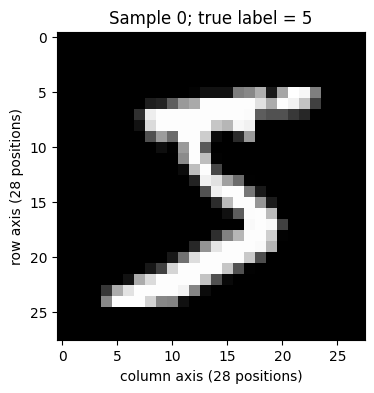

One image: rank 2 shape (28, 28) dtype uint8


interactive(children=(IntSlider(value=0, continuous_update=False, description='Image', max=99), Output()), _do…

In [2]:
(train_images, train_labels), (test_images, test_labels) = mnist.load_data()
assert train_images.shape == (60000, 28, 28)
assert test_images.shape == (10000, 28, 28)
assert train_labels.shape == (60000,) and test_labels.shape == (10000,)
print("Training images:", train_images.shape, train_images.dtype)
print("Training labels:", train_labels.shape, train_labels.dtype)
print("Test images:", test_images.shape)
print("Raw pixel range:", int(train_images.min()), "to", int(train_images.max()))

def show_digit(index=0):
    fig, ax = plt.subplots(figsize=(4, 4))
    ax.imshow(train_images[index], cmap="gray", vmin=0, vmax=255)
    ax.set(title=f"Sample {index}; true label = {train_labels[index]}",
           xlabel="column axis (28 positions)", ylabel="row axis (28 positions)")
    plt.show()
    plt.close(fig)
    print("One image: rank", train_images[index].ndim,
          "shape", train_images[index].shape, "dtype", train_images[index].dtype)

show_digit(0)  # Visible default even when a notebook viewer cannot render widgets.
digit_control = widgets.interactive(
    show_digit, index=widgets.IntSlider(value=0, min=0, max=99,
                                      description="Image", continuous_update=False))
display(digit_control)


## 2. Data representations: axes, slices, batches, and reshaping

Rank counts axes; shape gives the length of each axis; dtype describes the stored number type. A vector of 784 pixels has **one axis**, even though it contains 784 numbers. A single grayscale MNIST image has two axes. A batch has an additional sample axis.

We invent a four-dimensional example only to show axis bookkeeping: `(batch, height, width, channels)`. This is not an introduction to convolutional networks.


In [3]:
examples = {
    "scalar pixel": np.array(train_images[0, 14, 14]),
    "vector / one row": train_images[0, 14, :],
    "matrix / one image": train_images[0],
    "rank-3 image batch": train_images[:8],
    "rank-4 invented color batch": np.zeros((2, 3, 4, 3), dtype=np.uint8),
}
for name, array in examples.items():
    print(f"{name:29} rank={array.ndim}, shape={array.shape}, dtype={array.dtype}")

def inspect_batch(start=0, size=8):
    batch = train_images[start:start + size]
    flat = batch.reshape(len(batch), 28 * 28)
    normalized = flat.astype("float32") / 255.0
    print("Slice:", f"train_images[{start}:{start + size}]")
    print("Images → flat → normalized:", batch.shape, "→", flat.shape, "→", normalized.shape)
    print("Number of axes:", batch.ndim, "→", flat.ndim)
    print("dtype:", batch.dtype, "→", normalized.dtype)
    print("Normalized minimum / maximum:", float(normalized.min()), float(normalized.max()))
    assert batch.size == flat.size  # Reshaping changes organization, not element count.
    assert np.array_equal(flat.reshape(batch.shape), batch)

inspect_batch()
batch_control = widgets.interactive(
    inspect_batch,
    start=widgets.IntSlider(value=0, min=0, max=100, description="Start", continuous_update=False),
    size=widgets.IntSlider(value=8, min=1, max=32, description="Batch size", continuous_update=False))
display(batch_control)


scalar pixel                  rank=0, shape=(), dtype=uint8
vector / one row              rank=1, shape=(28,), dtype=uint8
matrix / one image            rank=2, shape=(28, 28), dtype=uint8
rank-3 image batch            rank=3, shape=(8, 28, 28), dtype=uint8
rank-4 invented color batch   rank=4, shape=(2, 3, 4, 3), dtype=uint8
Slice: train_images[0:8]
Images → flat → normalized: (8, 28, 28) → (8, 784) → (8, 784)
Number of axes: 3 → 2
dtype: uint8 → float32
Normalized minimum / maximum: 0.0 1.0


interactive(children=(IntSlider(value=0, continuous_update=False, description='Start'), IntSlider(value=8, con…

**Activity:** Choose batch size 1. Predict its shape before looking. Why does it keep a sample axis?

Next, move a crop across a digit. This is array slicing to inspect pixels, not a new preprocessing strategy for training. The classifier below still uses the full image.


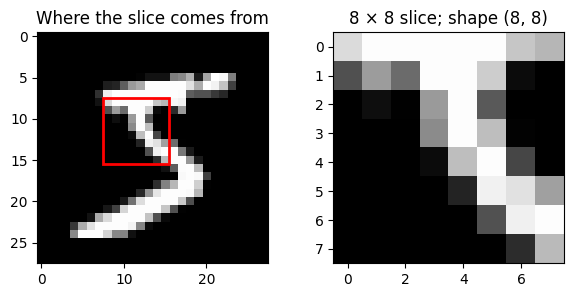

interactive(children=(IntSlider(value=8, continuous_update=False, description='Row', max=20), IntSlider(value=…

Original:
 [[0 1 2]
 [3 4 5]]
Reshape to (3, 2):
 [[0 1]
 [2 3]
 [4 5]]
Transpose to (3, 2):
 [[0 3]
 [1 4]
 [2 5]]


In [4]:
def inspect_crop(row=8, column=8):
    crop = train_images[0, row:row + 8, column:column + 8]
    fig, axes = plt.subplots(1, 2, figsize=(7, 3))
    axes[0].imshow(train_images[0], cmap="gray", vmin=0, vmax=255)
    axes[0].add_patch(plt.Rectangle((column - 0.5, row - 0.5), 8, 8,
                                   fill=False, edgecolor="red", linewidth=2))
    axes[0].set_title("Where the slice comes from")
    axes[1].imshow(crop, cmap="gray", vmin=0, vmax=255)
    axes[1].set_title(f"8 × 8 slice; shape {crop.shape}")
    plt.show()
    plt.close(fig)

inspect_crop()
crop_control = widgets.interactive(
    inspect_crop,
    row=widgets.IntSlider(value=8, min=0, max=20, description="Row", continuous_update=False),
    column=widgets.IntSlider(value=8, min=0, max=20, description="Column", continuous_update=False))
display(crop_control)

small = np.arange(6).reshape(2, 3)
print("Original:\n", small)
print("Reshape to (3, 2):\n", small.reshape(3, 2))
print("Transpose to (3, 2):\n", small.T)
assert not np.array_equal(small.reshape(3, 2), small.T)


**Check:** Both last arrays have shape `(3, 2)`. Explain why their values are arranged differently. Reshaping preserves flattened element order; transposition swaps axes.

## 3. Tensor operations: build one layer from small pieces

Start with two invented samples, each with three features. Multiplication combines each sample with each column of weights; adding a bias broadcasts one value per output feature across the samples. ReLU replaces negative values with zero.

Read `@` as matrix multiplication and `*` as element-wise multiplication. They are different operations.


In [5]:
tiny_inputs = np.array([[1., 2., 3.], [4., 5., 6.]], dtype="float32")
tiny_weights = np.array([[1., -1.], [0., 2.], [1., 0.]], dtype="float32")
tiny_bias = np.array([-3., 1.], dtype="float32")
product = tiny_inputs @ tiny_weights
preactivation = product + tiny_bias
activated = np.maximum(preactivation, 0)
print("(samples, inputs) @ (inputs, outputs) + (outputs,)")
print(tiny_inputs.shape, "@", tiny_weights.shape, "+", tiny_bias.shape, "→", activated.shape)
print("Matrix product:\n", product)
print("Broadcast bias:\n", np.broadcast_to(tiny_bias, product.shape))
print("Before ReLU:\n", preactivation)
print("After ReLU:\n", activated)
manual_00 = sum(tiny_inputs[0, j] * tiny_weights[j, 0] for j in range(3))
assert np.isclose(manual_00, product[0, 0])
assert np.array_equal(activated, np.array([[1., 4.], [7., 7.]], dtype="float32"))
print("One dot product, checked by hand:", manual_00)
print("Element-wise square, same input shape:\n", tiny_inputs * tiny_inputs)


(samples, inputs) @ (inputs, outputs) + (outputs,)
(2, 3) @ (3, 2) + (2,) → (2, 2)
Matrix product:
 [[ 4.  3.]
 [10.  6.]]
Broadcast bias:
 [[-3.  1.]
 [-3.  1.]]
Before ReLU:
 [[1. 4.]
 [7. 7.]]
After ReLU:
 [[1. 4.]
 [7. 7.]]
One dot product, checked by hand: 4.0
Element-wise square, same input shape:
 [[ 1.  4.  9.]
 [16. 25. 36.]]


### Weight and bias controls

An invented one-input, one-output layer is easier to see than 784 pixels at once. Its output before activation is `z = w*x + b`. The weight changes the slope and the bias shifts the line. ReLU then bends the transformation at zero.

**Predict first:** What will a negative weight do? What changes if you increase only the bias? Can two different negative inputs become the same output after ReLU?


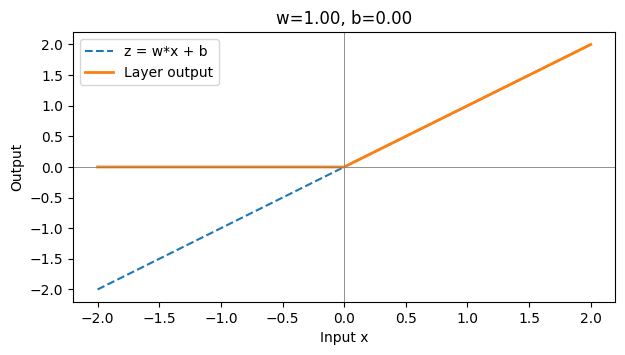

At x=1: before activation = 1.0 ; output = 1.0


interactive(children=(FloatSlider(value=1.0, continuous_update=False, description='Weight', max=3.0, min=-3.0,…

In [6]:
def view_neuron(weight=1.0, bias=0.0, use_relu=True):
    x_values = np.linspace(-2, 2, 101)
    z_values = weight * x_values + bias
    output_values = np.maximum(z_values, 0) if use_relu else z_values
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.plot(x_values, z_values, "--", label="z = w*x + b")
    ax.plot(x_values, output_values, label="Layer output", linewidth=2)
    ax.axhline(0, color="gray", linewidth=0.6)
    ax.axvline(0, color="gray", linewidth=0.6)
    ax.set(xlabel="Input x", ylabel="Output", title=f"w={weight:.2f}, b={bias:.2f}")
    ax.legend()
    plt.show()
    plt.close(fig)
    print("At x=1: before activation =", weight + bias,
          "; output =", max(weight + bias, 0) if use_relu else weight + bias)

view_neuron()
neuron_control = widgets.interactive(
    view_neuron,
    weight=widgets.FloatSlider(value=1., min=-3., max=3., step=0.25, description="Weight", continuous_update=False),
    bias=widgets.FloatSlider(value=0., min=-3., max=3., step=0.25, description="Bias", continuous_update=False),
    use_relu=widgets.Checkbox(value=True, description="Apply ReLU"))
display(neuron_control)


## 4. Geometry: rows of a tensor are points

The chapter connects tensor operations to geometry. Here 100 invented points form a circle. Multiplying their coordinates by a small matrix stretches or rotates them; adding a vector translates them. ReLU can collapse negative coordinates onto an axis.

These are visualizations of operations, not trained embeddings or a new model. Change one control at a time and describe which tensor operation caused the movement.


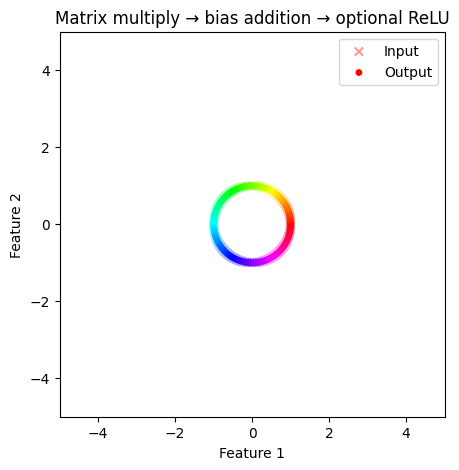

(100, 2) @ (2, 2) + (2,) → (100, 2)


interactive(children=(IntSlider(value=0, continuous_update=False, description='Angle', max=180, min=-180, step…

In [7]:
angles = np.linspace(0, 2 * np.pi, 100, endpoint=False)
points = np.column_stack([np.cos(angles), np.sin(angles)])

def transform_points(angle=0, scale=1.0, shift=0.0, use_relu=False):
    radians = np.deg2rad(angle)
    matrix = scale * np.array([[np.cos(radians), np.sin(radians)],
                               [-np.sin(radians), np.cos(radians)]])
    transformed = points @ matrix + np.array([shift, 0.0])
    if use_relu:
        transformed = np.maximum(transformed, 0)
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.scatter(*points.T, c=angles, cmap="hsv", marker="x", alpha=0.4, label="Input")
    ax.scatter(*transformed.T, c=angles, cmap="hsv", s=15, label="Output")
    ax.set(xlim=(-5, 5), ylim=(-5, 5), xlabel="Feature 1", ylabel="Feature 2",
           title="Matrix multiply → bias addition → optional ReLU")
    ax.set_aspect("equal")
    ax.legend()
    plt.show()
    plt.close(fig)
    print("(100, 2) @", matrix.shape, "+ (2,) →", transformed.shape)

transform_points()
geometry_control = widgets.interactive(
    transform_points,
    angle=widgets.IntSlider(value=0, min=-180, max=180, step=15, description="Angle", continuous_update=False),
    scale=widgets.FloatSlider(value=1., min=0.25, max=2., step=0.25, description="Scale", continuous_update=False),
    shift=widgets.FloatSlider(value=0., min=-2., max=2., step=0.25, description="Shift x", continuous_update=False),
    use_relu=widgets.Checkbox(value=False, description="Apply ReLU"))
display(geometry_control)


## 5. Optimization: how large should one step be?

Use the invented loss `L(w) = (w - 2)²`. Its minimum is deliberately visible, so we can check whether an update moves toward it. This is **not** the MNIST loss or a claim that real neural-network losses have this simple shape.

The derivative is `2*(w - 2)`. It tells us how the loss changes locally as the weight changes. Gradient descent uses `new_weight = weight - learning_rate * gradient`.

We compare the analytic derivative with a small finite difference and TensorFlow's automatic differentiation. The automatic version builds the operations while the tape is recording and applies the chain rule.


Analytic / finite difference / automatic: -3.0 -2.9999999999996696 -3.0


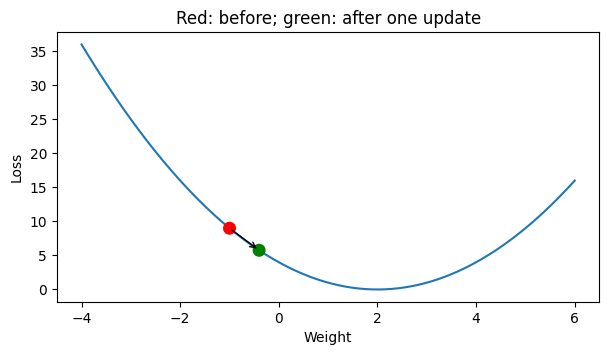

Gradient=-6.000; new w=-1.000 - 0.100 * -6.000 = -0.400
Loss: 9.0000 → 5.7600


interactive(children=(FloatSlider(value=-1.0, continuous_update=False, description='Weight', max=5.0, min=-3.0…

In [8]:
def scalar_loss(weight):
    return (weight - 2.0) ** 2

probe = tf.Variable(0.5, dtype=tf.float32)
with tf.GradientTape() as tape:
    probe_loss = (probe - 2.0) ** 2
automatic_gradient = float(tape.gradient(probe_loss, probe).numpy())
epsilon = 1e-4
finite_difference = (scalar_loss(0.5 + epsilon) - scalar_loss(0.5 - epsilon)) / (2 * epsilon)
analytic_gradient = 2 * (0.5 - 2)
print("Analytic / finite difference / automatic:", analytic_gradient, finite_difference, automatic_gradient)
assert np.isclose(analytic_gradient, finite_difference, atol=1e-5)
assert np.isclose(analytic_gradient, automatic_gradient)

def show_step(weight=-1.0, learning_rate=0.1):
    gradient = 2 * (weight - 2)
    next_weight = weight - learning_rate * gradient
    grid = np.linspace(min(-4, next_weight - 1), max(6, next_weight + 1), 300)
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.plot(grid, scalar_loss(grid), label="Loss curve")
    ax.scatter([weight, next_weight], [scalar_loss(weight), scalar_loss(next_weight)],
               c=["red", "green"], s=70, zorder=3)
    ax.annotate("", xy=(next_weight, scalar_loss(next_weight)),
                xytext=(weight, scalar_loss(weight)), arrowprops={"arrowstyle":"->"})
    ax.set(xlabel="Weight", ylabel="Loss", title="Red: before; green: after one update")
    plt.show()
    plt.close(fig)
    print(f"Gradient={gradient:.3f}; new w={weight:.3f} - {learning_rate:.3f} * {gradient:.3f} = {next_weight:.3f}")
    print(f"Loss: {scalar_loss(weight):.4f} → {scalar_loss(next_weight):.4f}")

show_step()
step_control = widgets.interactive(
    show_step,
    weight=widgets.FloatSlider(value=-1., min=-3., max=5., step=0.25, description="Weight", continuous_update=False),
    learning_rate=widgets.FloatSlider(value=0.1, min=0.01, max=1.2, step=0.01, description="Step size", continuous_update=False))
display(step_control)


**Activity:** Start at `w=-1`. Try learning rates 0.05, 0.5, 1.0, and 1.1. Predict each next weight. Does a step across the minimum always mean a larger loss? Does a positive learning rate always lower the loss?

Now repeat the exact same update. The horizontal axis in the next chart counts **updates**, not epochs or samples. The values of 0.5 and 1.0 have special behavior only because of this particular loss curve.


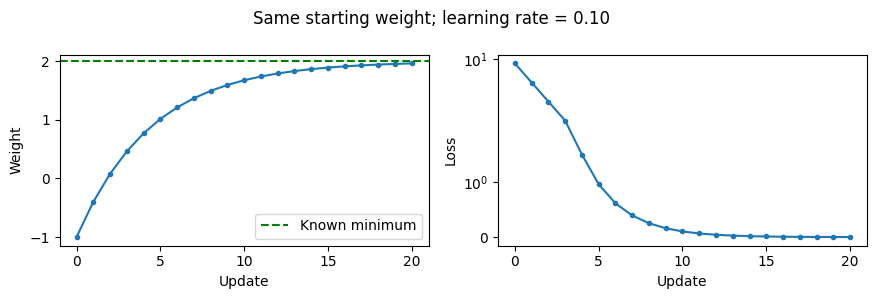

First / last loss: 9.0 0.001196305196206427


interactive(children=(FloatSlider(value=0.1, continuous_update=False, description='Step size', max=1.2, min=0.…

In [9]:
def descent_history(start, learning_rate, steps):
    weights = [float(start)]
    for _ in range(steps):
        weights.append(weights[-1] - learning_rate * 2 * (weights[-1] - 2))
    weights = np.array(weights)
    return weights, scalar_loss(weights)

def show_descent(learning_rate=0.1, steps=20):
    weights, losses = descent_history(-1.0, learning_rate, steps)
    fig, axes = plt.subplots(1, 2, figsize=(9, 3))
    axes[0].plot(weights, marker=".")
    axes[0].axhline(2, color="green", linestyle="--", label="Known minimum")
    axes[0].set(xlabel="Update", ylabel="Weight")
    axes[0].legend()
    axes[1].plot(losses, marker=".")
    axes[1].set(xlabel="Update", ylabel="Loss", yscale="symlog")
    fig.suptitle(f"Same starting weight; learning rate = {learning_rate:.2f}")
    plt.tight_layout()
    plt.show()
    plt.close(fig)
    print("First / last loss:", float(losses[0]), float(losses[-1]))

show_descent()
descent_control = widgets.interactive(
    show_descent,
    learning_rate=widgets.FloatSlider(value=0.1, min=0.01, max=1.2, step=0.01, description="Step size", continuous_update=False),
    steps=widgets.IntSlider(value=20, min=1, max=30, description="Updates", continuous_update=False))
display(descent_control)
assert descent_history(-1, 0.1, 20)[1][-1] < scalar_loss(-1)
assert descent_history(-1, 1.1, 20)[1][-1] > scalar_loss(-1)


## 6. Backpropagation: trace one chain before trusting the tape

Use invented values `x=2`, `w=0.5`, `b=0.1`, and target `y=2`. The calculation has two stages:

1. Prediction `p = w*x + b`.
2. Loss `L = (p-y)²`.

The chain rule combines the derivative of loss with respect to prediction, `2*(p-y)`, with the derivative of prediction with respect to weight, `x`. The resulting weight gradient is `2*(p-y)*x`; the bias gradient is `2*(p-y)`.

**Ask first:** Are the weight and bias gradients equal here? Why does the input value appear in one of them?


In [10]:
x = tf.constant(2.0)
target = tf.constant(2.0)
w = tf.Variable(0.5)
b = tf.Variable(0.1)
with tf.GradientTape() as tape:
    prediction = w * x + b
    loss = (prediction - target) ** 2
grad_w, grad_b = tape.gradient(loss, [w, b])
chain_w = 2 * (prediction - target) * x
chain_b = 2 * (prediction - target)
np.testing.assert_allclose(grad_w.numpy(), chain_w.numpy())
np.testing.assert_allclose(grad_b.numpy(), chain_b.numpy())
print("Prediction / target / loss:", float(prediction), float(target), float(loss))
print("Chain rule gradients:", float(chain_w), float(chain_b))
print("Tape gradients:", float(grad_w), float(grad_b))


Prediction / target / loss: 1.100000023841858 2.0 0.809999942779541
Chain rule gradients: -3.5999999046325684 -1.7999999523162842
Tape gradients: -3.5999999046325684 -1.7999999523162842


## 7. Looking back: teach a small network to classify real digits

Now connect the pieces. We use **6,000 training images**, **1,000 test images**, a **32-unit ReLU layer**, and **10 output scores**. These smaller sizes are deliberate teaching choices for a short CPU run, not a change to the official notebook. We do not promise the book's reported accuracy.

| Tensor | Shape | Meaning |
|---|---|---|
| X | (batch, 784) | Flattened, normalized images |
| W1, b1 | (784, 32), (32,) | Hidden-layer parameters |
| h = ReLU(X @ W1 + b1) | (batch, 32) | Learned hidden representation |
| W2, b2 | (32, 10), (10,) | Output-layer parameters |
| scores = h @ W2 + b2 | (batch, 10) | Raw class scores (logits) |
| softmax(scores) | (batch, 10) | Class probability scores summing to 1 |
| labels | (batch,) | Correct digit numbers |

We use TensorFlow's stable sparse softmax cross-entropy on raw scores. It combines softmax and the classification loss internally; do **not** pass already-softmaxed probabilities to that function. Softmax is explicit below when displaying predictions. No derivation of cross-entropy is required for this lesson.

The update is **mini-batch SGD**: average the batch losses, calculate gradients, and subtract learning rate × gradient for every parameter. An epoch is one pass through all training samples. Batches within an epoch can have different losses; progress need not be monotonic at every step.


In [11]:
TRAIN_SIZE = 6000
TEST_SIZE = 1000
BATCH_SIZE = 128
HIDDEN_UNITS = 32

x_train = train_images[:TRAIN_SIZE].reshape(TRAIN_SIZE, 784).astype("float32") / 255.0
y_train = train_labels[:TRAIN_SIZE].astype("int64")
x_test = test_images[:TEST_SIZE].reshape(TEST_SIZE, 784).astype("float32") / 255.0
y_test = test_labels[:TEST_SIZE].astype("int64")
assert x_train.shape == (6000, 784) and x_test.shape == (1000, 784)
assert 0 <= x_train.min() <= x_train.max() <= 1
print("Training data and labels:", x_train.shape, y_train.shape)
print("Held-out data and labels:", x_test.shape, y_test.shape)

def make_parameters():
    # Explicit stateless seeds mean each training comparison starts identically.
    return [
        tf.Variable(tf.random.stateless_normal((784, HIDDEN_UNITS), seed=[SEED, 1], stddev=0.05), name="W1"),
        tf.Variable(tf.zeros(HIDDEN_UNITS), name="b1"),
        tf.Variable(tf.random.stateless_normal((HIDDEN_UNITS, 10), seed=[SEED, 2], stddev=0.05), name="W2"),
        tf.Variable(tf.zeros(10), name="b2"),
    ]

def forward(inputs, parameters):
    W1, b1, W2, b2 = parameters
    hidden = tf.nn.relu(tf.matmul(inputs, W1) + b1)
    scores = tf.matmul(hidden, W2) + b2
    return hidden, scores

def batch_loss(inputs, labels, parameters):
    _, scores = forward(inputs, parameters)
    return tf.reduce_mean(tf.nn.sparse_softmax_cross_entropy_with_logits(labels=labels, logits=scores))

def classification_accuracy(inputs, labels, parameters):
    _, scores = forward(inputs, parameters)
    predicted = tf.argmax(scores, axis=1, output_type=tf.int64)
    return float(tf.reduce_mean(tf.cast(predicted == labels, tf.float32)).numpy())

def training_step(inputs, labels, parameters, learning_rate):
    with tf.GradientTape() as tape:
        loss = batch_loss(inputs, labels, parameters)
    gradients = tape.gradient(loss, parameters)
    for parameter, gradient in zip(parameters, gradients):
        if gradient is None:
            raise RuntimeError("Missing gradient: inspect the forward pass before continuing.")
        tf.debugging.assert_all_finite(gradient, "Non-finite gradient; inspect inputs and learning rate")
        parameter.assign_sub(learning_rate * gradient)
    return float(loss.numpy()), gradients

demo_parameters = make_parameters()
hidden, scores = forward(x_train[:8], demo_parameters)
probabilities = tf.nn.softmax(scores, axis=1).numpy()
print("One forward pass:", x_train[:8].shape, "→", hidden.shape, "→", scores.shape)
print("Probability row sums:", probabilities.sum(axis=1))
np.testing.assert_allclose(probabilities.sum(axis=1), 1, atol=1e-6)
_, demo_gradients = training_step(x_train[:8], y_train[:8], demo_parameters, learning_rate=0.1)
print("Parameter shapes:", [tuple(p.shape) for p in demo_parameters])
print("Gradient shapes: ", [tuple(g.shape) for g in demo_gradients])
assert all(p.shape == g.shape for p, g in zip(demo_parameters, demo_gradients))


Training data and labels: (6000, 784) (6000,)
Held-out data and labels: (1000, 784) (1000,)


One forward pass: (8, 784) → (8, 32) → (8, 10)
Probability row sums: [1.         1.         1.         1.         0.99999994 1.
 1.         1.        ]


Parameter shapes: [(784, 32), (32,), (32, 10), (10,)]
Gradient shapes:  [(784, 32), (32,), (32, 10), (10,)]


### Training controls: choose, then run

The sliders below **only select settings**. They do not start training on every movement. Set them, then run the following training cell. Each run creates fresh parameters and the same shuffle sequence, so comparisons change the setting you chose rather than the starting network.

Start with defaults. If you later compare learning rates, use training loss for that demonstration; keep the held-out test set for the final evaluation rather than using it to choose the best setting.


In [12]:
training_rate = widgets.FloatLogSlider(value=0.1, base=10, min=-3, max=-0.3, step=0.1,
                                       description="Learn rate", continuous_update=False)
training_epochs = widgets.IntSlider(value=3, min=1, max=5, description="Epochs", continuous_update=False)
display(widgets.VBox([training_rate, training_epochs]))
print("Defaults: learning rate=0.1, epochs=3. Set controls, then run the next cell.")

def train_network(learning_rate, epochs):
    parameters = make_parameters()
    shuffle = np.random.default_rng(SEED)
    initial_loss = float(batch_loss(x_train, y_train, parameters).numpy())
    initial_accuracy = classification_accuracy(x_train, y_train, parameters)
    loss_history = [initial_loss]
    print(f"Before training: training loss={initial_loss:.4f}, accuracy={initial_accuracy:.3f}")
    for epoch in range(epochs):
        order = shuffle.permutation(len(x_train))
        for start in range(0, len(order), BATCH_SIZE):
            indices = order[start:start + BATCH_SIZE]
            training_step(x_train[indices], y_train[indices], parameters, learning_rate)
        # Evaluate at the end of the epoch using the current parameters.
        loss_now = float(batch_loss(x_train, y_train, parameters).numpy())
        accuracy_now = classification_accuracy(x_train, y_train, parameters)
        loss_history.append(loss_now)
        print(f"Epoch {epoch + 1}: training loss={loss_now:.4f}, accuracy={accuracy_now:.3f}")
    return parameters, np.array(loss_history)


Defaults: learning rate=0.1, epochs=3. Set controls, then run the next cell.


Before training: training loss=2.3098, accuracy=0.106


Epoch 1: training loss=1.4206, accuracy=0.674


Epoch 2: training loss=0.7368, accuracy=0.815


Epoch 3: training loss=0.5382, accuracy=0.858


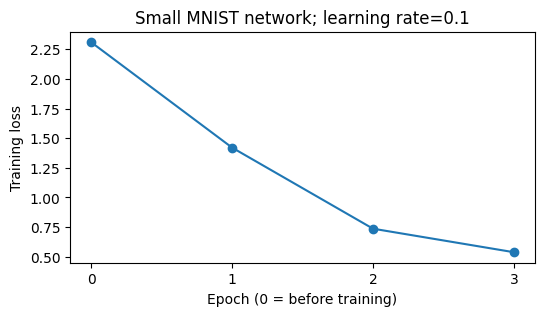

Observed loss change: -1.7715303301811218


In [13]:
# Rerun this cell after changing the training controls above.
chosen_rate = float(training_rate.value)
chosen_epochs = int(training_epochs.value)
parameters, loss_history = train_network(chosen_rate, chosen_epochs)
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(np.arange(len(loss_history)), loss_history, marker="o")
ax.set(xlabel="Epoch (0 = before training)", ylabel="Training loss",
       title=f"Small MNIST network; learning rate={chosen_rate:.4g}")
ax.set_xticks(range(len(loss_history)))
plt.show()
plt.close(fig)
print("Observed loss change:", float(loss_history[-1] - loss_history[0]))


### Evaluate and inspect predictions

Only after the training demonstration do we evaluate on the separate test subset. Accuracy and loss answer different questions: accuracy counts correct top choices; loss also reflects the probability assigned to the correct answer.

A model can be wrong even when its largest probability score is high. An image browser makes that more concrete than a single accuracy number. A wrong example is an observation to explain, not a reason to pretend the run failed.


Held-out subset: 1000 images; loss=0.6343; accuracy=0.821
Incorrect predictions in this subset: 179


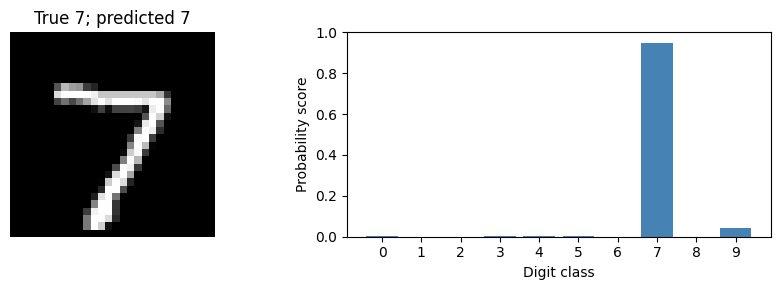

interactive(children=(IntSlider(value=0, continuous_update=False, description='Test image', max=999), Output()…

Try one misclassified example by setting the slider to: 8


In [14]:
_, test_scores = forward(x_test, parameters)
test_probabilities = tf.nn.softmax(test_scores, axis=1).numpy()
predicted_labels = test_probabilities.argmax(axis=1)
test_accuracy = float(np.mean(predicted_labels == y_test))
test_loss = float(batch_loss(x_test, y_test, parameters).numpy())
print(f"Held-out subset: {TEST_SIZE} images; loss={test_loss:.4f}; accuracy={test_accuracy:.3f}")
wrong_indices = np.flatnonzero(predicted_labels != y_test)
print("Incorrect predictions in this subset:", len(wrong_indices))
np.testing.assert_allclose(test_probabilities.sum(axis=1), 1, atol=1e-6)

def inspect_prediction(index=0):
    fig, axes = plt.subplots(1, 2, figsize=(9, 3))
    axes[0].imshow(test_images[index], cmap="gray", vmin=0, vmax=255)
    axes[0].set_title(f"True {y_test[index]}; predicted {predicted_labels[index]}")
    axes[0].axis("off")
    axes[1].bar(range(10), test_probabilities[index], color="steelblue")
    axes[1].set(xlabel="Digit class", ylabel="Probability score", ylim=(0, 1), xticks=range(10))
    plt.tight_layout()
    plt.show()
    plt.close(fig)

inspect_prediction()
prediction_control = widgets.interactive(
    inspect_prediction,
    index=widgets.IntSlider(value=0, min=0, max=TEST_SIZE - 1, description="Test image", continuous_update=False))
display(prediction_control)
if len(wrong_indices):
    print("Try one misclassified example by setting the slider to:", int(wrong_indices[0]))


## 8. Teach-back and run record

Explain these in your own words, pointing to actual values above:

1. Why is a batch shaped `(8, 28, 28)` before reshaping and `(8, 784)` afterward? Which axis represents samples?
2. Calculate one output in the tiny matrix example by hand, including its bias and ReLU.
3. Explain what broadcasting repeats, and why `@` and `*` cannot be interchanged.
4. Use the learning-rate controls to demonstrate a decreasing loss and an overshooting update. Explain the gradient sign.
5. Trace the chain rule through the invented neuron. Why must each gradient have the same shape as its parameter?
6. Describe one MNIST batch update without saying “the model learns automatically.” Point to the forward pass, loss, gradient, and assignment.
7. Show a correct prediction and, if available, an incorrect one. Explain why test accuracy need not equal training accuracy.

**Mini-experiment:** Record the toy loss trajectories for learning rates 0.05, 0.5, and 1.1. For each, write your prediction first and then your observation. Optionally change the MNIST learning rate once, keeping the same initial weights and number of epochs; compare **training** loss without selecting settings using test accuracy.

The next cell prints a small run summary. Save it in `../RUN_LOG.md`, record your explanations in `../EXERCISES.md`, and add any environment edits to `../NOTEBOOK_CHANGES.md`. Saving a notebook in Colab does not automatically update this repository. Download the executed `.ipynb` back into this experiment folder when ready to preserve it.


In [15]:
run_summary = {
    "experiment": "Chapter 2 interactive foundations lab",
    "completed_at_utc": datetime.now(timezone.utc).isoformat(),
    "environment": environment,
    "dataset": "MNIST (real handwritten digits)",
    "training_samples": TRAIN_SIZE,
    "test_samples": TEST_SIZE,
    "hidden_units": HIDDEN_UNITS,
    "batch_size": BATCH_SIZE,
    "learning_rate": chosen_rate,
    "epochs": chosen_epochs,
    "initial_training_loss": float(loss_history[0]),
    "final_training_loss": float(loss_history[-1]),
    "test_loss": test_loss,
    "test_accuracy": test_accuracy,
    "environment_changes_this_session": "Fill in if you changed packages or code",
    "widget_interactions": "Record settings actually tried; a Run all is not a manual interaction check",
}
print(json.dumps(run_summary, indent=2))


{
  "experiment": "Chapter 2 interactive foundations lab",
  "completed_at_utc": "2026-10-15T12:12:52.287829+00:00",
  "environment": {
    "recorded_at_utc": "2026-10-15T12:12:44.937667+00:00",
    "python": "3.10.0",
    "platform": "Windows-10-10.0.19044-SP0",
    "backend": "tensorflow (explicit TensorFlow operations)",
    "packages": {
      "numpy": "1.24.1",
      "matplotlib": "3.7.0",
      "tensorflow": "2.11.0",
      "keras": "2.11.0",
      "ipywidgets": "8.1.5"
    },
    "devices": [
      "/physical_device:CPU:0"
    ],
    "seed": 2026
  },
  "dataset": "MNIST (real handwritten digits)",
  "training_samples": 6000,
  "test_samples": 1000,
  "hidden_units": 32,
  "batch_size": 128,
  "learning_rate": 0.1,
  "epochs": 3,
  "initial_training_loss": 2.309777021408081,
  "final_training_loss": 0.5382466912269592,
  "test_loss": 0.6343199014663696,
  "test_accuracy": 0.821,
  "environment_changes_this_session": "Fill in if you changed packages or code",
  "widget_interactio

**Learner notes to fill after the activities**

- My explanation of rank versus shape:
- My hand-calculated matrix output:
- My learning-rate predictions and observations:
- My explanation of one gradient update:
- A surprising or incorrect MNIST prediction:
- Environment changes, if any, and why:
- What remains unclear:

**Resume point:** Complete this teach-back and record the run. Chapter 2 is ready for its recap/completion review afterward; the next reading is the beginning of Chapter 3.
